# Einzelne $P_{B,z}$-Maps plotten

Dieses Notebook liest den mit `detail = true` erzeugten CSV-Export aus `output/data/support/`. CSV-Pfad und Observable-Bin werden direkt an die Plotfunktion übergeben.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Hilfsfunktionen

Relative Pfade beziehen sich auf das Projektverzeichnis, aus dem Jupyter gestartet wurde.

In [2]:
required_columns = {
    "observable_bin", "iq", "ix",
    "log10_q2_low", "log10_q2_high",
    "log10_x_low", "log10_x_high", "p_bz",
}

In [3]:
def load_support_data(csv_path):
    csv_path = Path(csv_path)
    data = pd.read_csv(csv_path)
    missing = required_columns.difference(data.columns)
    if missing:
        raise ValueError(f"CSV is missing columns: {sorted(missing)}")

    available_bins = sorted(data["observable_bin"].unique())
    return csv_path, data, available_bins

In [4]:
def plot_support_bin(csv_path, observable_bin, *, title=None, save_path=None, cmap="Blues", color_range=(0.0, 0.5)):
    if color_range is None:
        vmin, vmax = None, None
    else:
        vmin, vmax = color_range
        if not vmin < vmax:
            raise ValueError("color_range must satisfy min < max")
    csv_path, data, available_bins = load_support_data(csv_path)
    if observable_bin is None:
        cell_columns = [
            "iq", "ix", "log10_q2_low", "log10_q2_high",
            "log10_x_low", "log10_x_high",
        ]
        selected = data.groupby(cell_columns, as_index=False)["p_bz"].sum()
        colorbar_label = r"$\sum_B P_{B,z}$"
    else:
        selected = data[data["observable_bin"] == observable_bin].copy()
        if selected.empty:
            raise ValueError(
                f"Observable bin {observable_bin} is unavailable; choose one of {available_bins}"
            )
        colorbar_label = r"$P_{B,z}$"

    nx = int(selected["ix"].max()) + 1
    nq = int(selected["iq"].max()) + 1
    if len(selected) != nx * nq:
        raise ValueError("Selected bin does not contain a complete rectangular grid")

    weights = np.full((nq, nx), np.nan)
    weights[
        selected["iq"].to_numpy(dtype=int),
        selected["ix"].to_numpy(dtype=int),
    ] = selected["p_bz"].to_numpy(dtype=float)

    x_cells = (
        selected[["ix", "log10_x_low", "log10_x_high"]]
        .drop_duplicates("ix")
        .sort_values("ix")
    )
    q2_cells = (
        selected[["iq", "log10_q2_low", "log10_q2_high"]]
        .drop_duplicates("iq")
        .sort_values("iq")
    )

    log_x_edges = np.r_[
        x_cells["log10_x_low"].to_numpy(),
        x_cells["log10_x_high"].iloc[-1],
    ]
    log_q2_edges = np.r_[
        q2_cells["log10_q2_low"].to_numpy(),
        q2_cells["log10_q2_high"].iloc[-1],
    ]
    x_edges = np.power(10.0, log_x_edges)
    q2_edges = np.power(10.0, log_q2_edges)

    fig, ax = plt.subplots(figsize=(7.5, 6.0), constrained_layout=True)
    mesh = ax.pcolormesh(
        x_edges, q2_edges, weights, shading="flat", cmap=cmap,
        vmin=vmin, vmax=vmax,
        edgecolors=(0.0, 0.0, 0.0, 0.25), linewidth=0.2,
    )
    colorbar = fig.colorbar(mesh, ax=ax)
    colorbar.set_label(colorbar_label, fontsize=18)
    colorbar.ax.tick_params(labelsize=12)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$x$", fontsize=16)
    ax.set_ylabel(r"$\mu^2\;[\mathrm{GeV}^2]$", fontsize=16)
    ax.tick_params(axis="both", which="major", labelsize=12)
    if title is None:
        if observable_bin is None:
            title = rf"{csv_path.stem}: sum over all observable bins"
        else:
            title = rf"{csv_path.stem}: observable bin $B={observable_bin}$"
    ax.set_title(title, fontsize=16)
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
        print(f"Saved {save_path}")
    return fig, ax


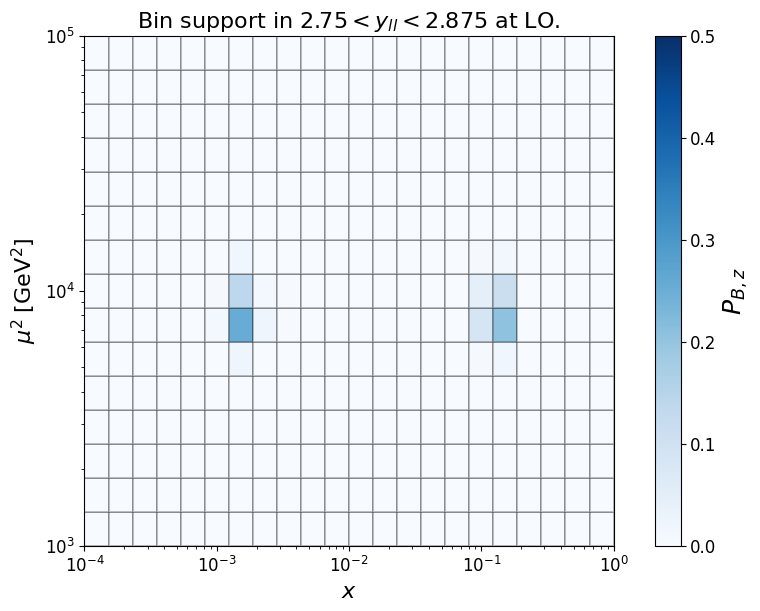

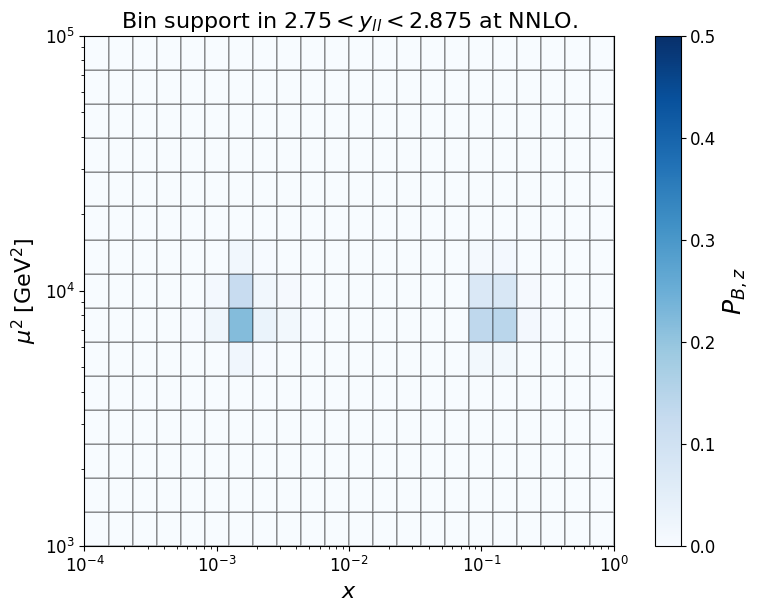

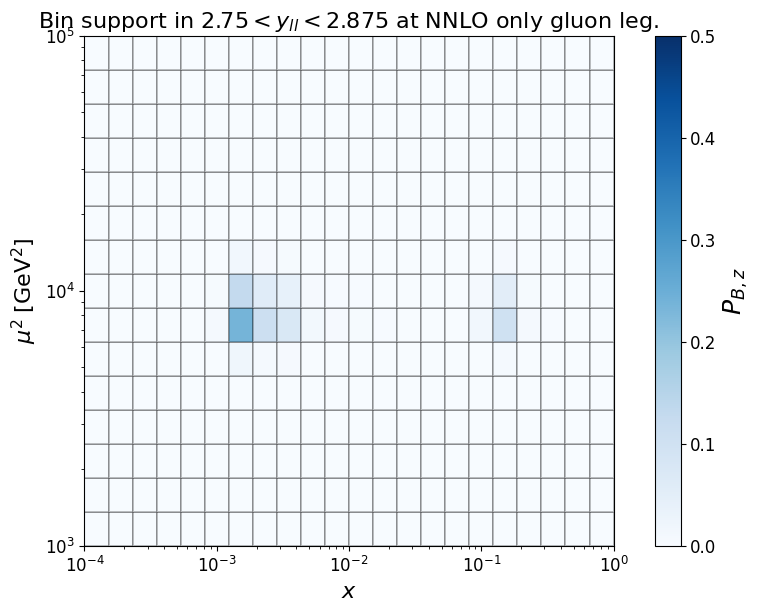

In [17]:


# plot_support_bin(
#     "/home/jnieh/uni/projects/gridsense/output/data/support/z0_lhcb_LO_11_8.csv",
#     bin,
# );
# plot_support_bin(
#     "/home/jnieh/uni/projects/gridsense/output/data/support/z0_lhcb_NLO_11_8.csv",
#     bin,
# );

bin = 2
plot_support_bin(
        "/home/jnieh/uni/projects/gridsense/output/data/support/z0_lhcb_LO.csv",
        bin,
        color_range=(0.0, 0.5),
        title=r"Bin support in $2.75 < y_{ll} < 2.875$ at LO.",
        #save_path="/home/jnieh/uni/projects/gridsense/output/plots/per_bin/z0_lhcb_bin_6_LO.pdf",
    );
plot_support_bin(
        "/home/jnieh/uni/projects/gridsense/output/data/support/z0_lhcb_NNLO.csv",
        bin,
        color_range=(0.0, 0.5),
        title=r"Bin support in $2.75 < y_{ll} < 2.875$ at NNLO.",
        #save_path="/home/jnieh/uni/projects/gridsense/output/plots/per_bin/z0_lhcb_bin_6_NLO.pdf",
    );
plot_support_bin(
        "/home/jnieh/uni/projects/gridsense/output/data/support/z0_lhcb_NNLO_gleg.csv",
        bin,
        color_range=(0.0, 0.5),
        title=r"Bin support in $2.75 < y_{ll} < 2.875$ at NNLO only gluon leg.",
       # save_path="/home/jnieh/uni/projects/gridsense/output/plots/per_bin/z0_lhcb_bin_6_NLO_gluon.pdf",

 );

# plot_support_bin(
#     "/home/jnieh/uni/projects/gridsense/output/data/support/z0_lhcb_NLO_15_10_gluon.csv",
#     bin,
# );

# TTBAR

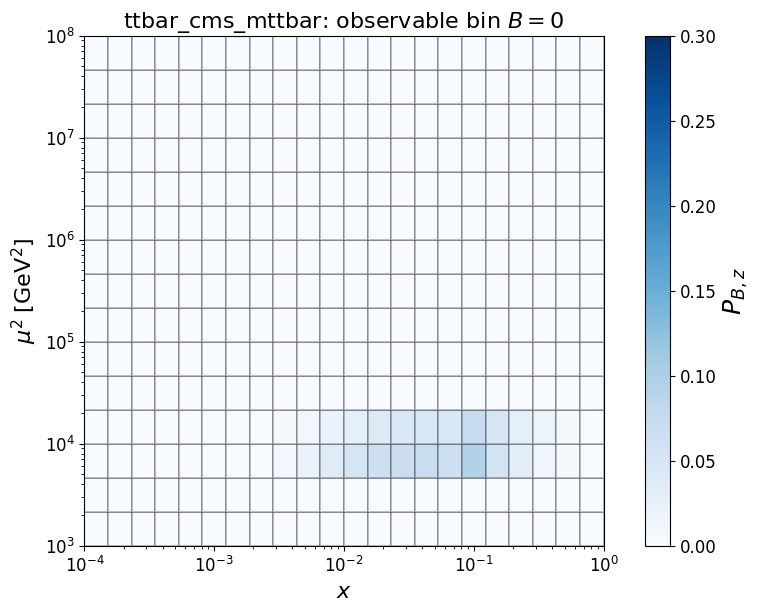

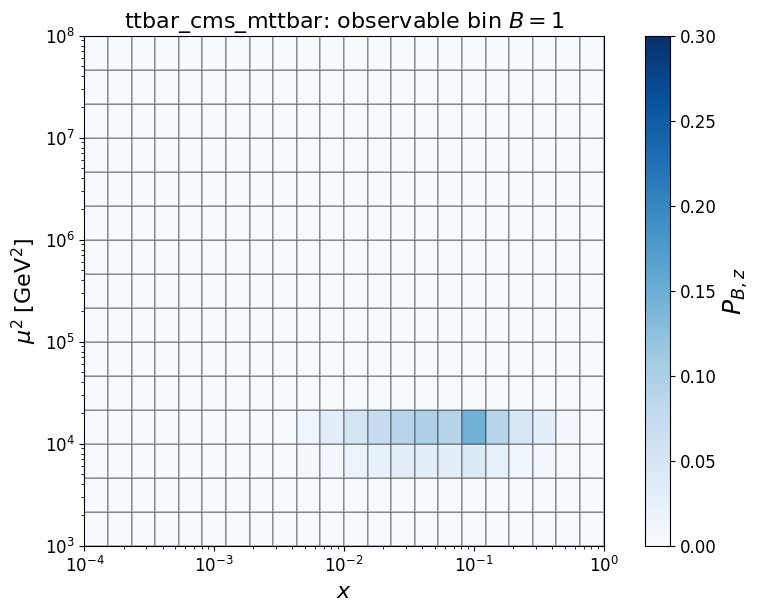

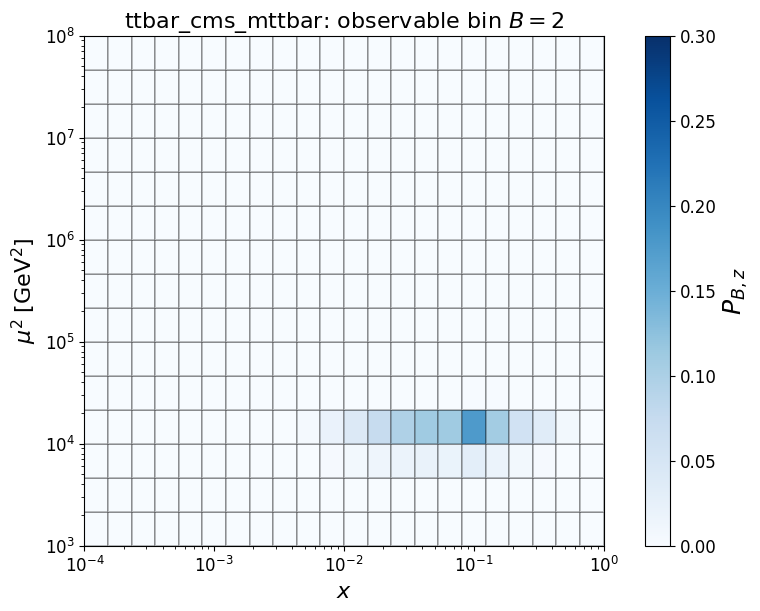

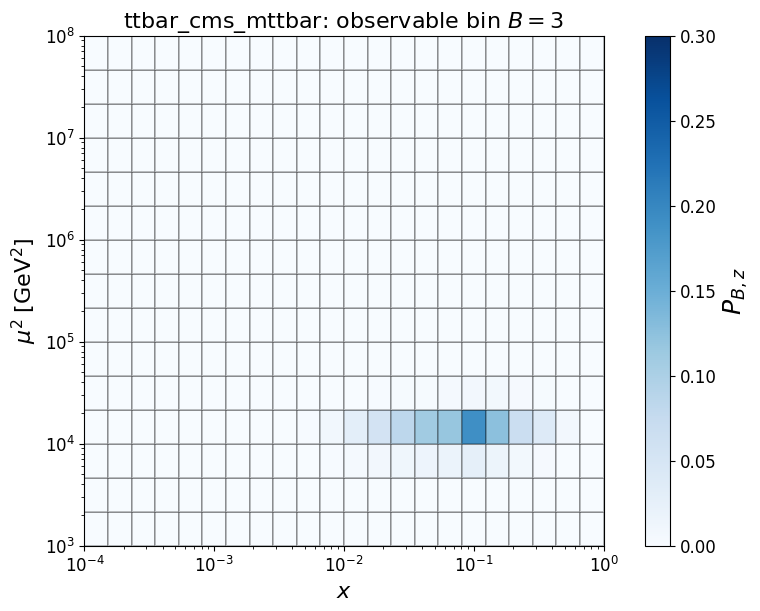

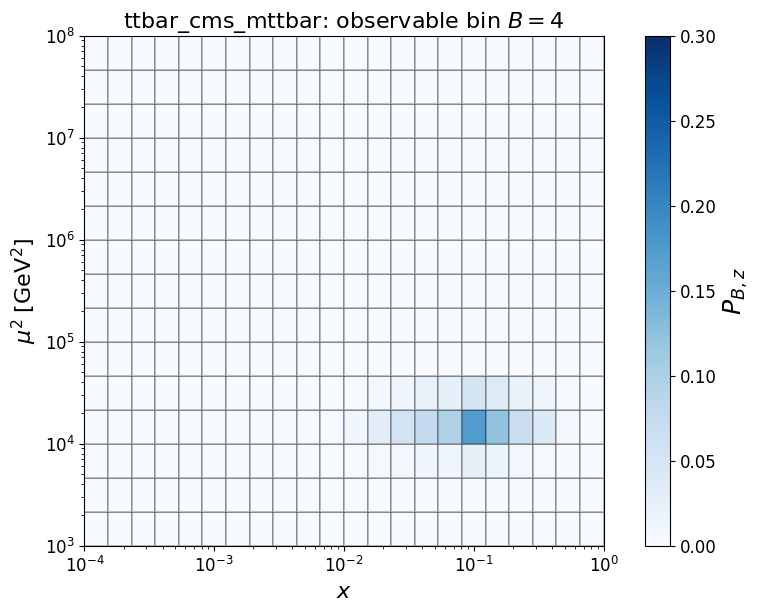

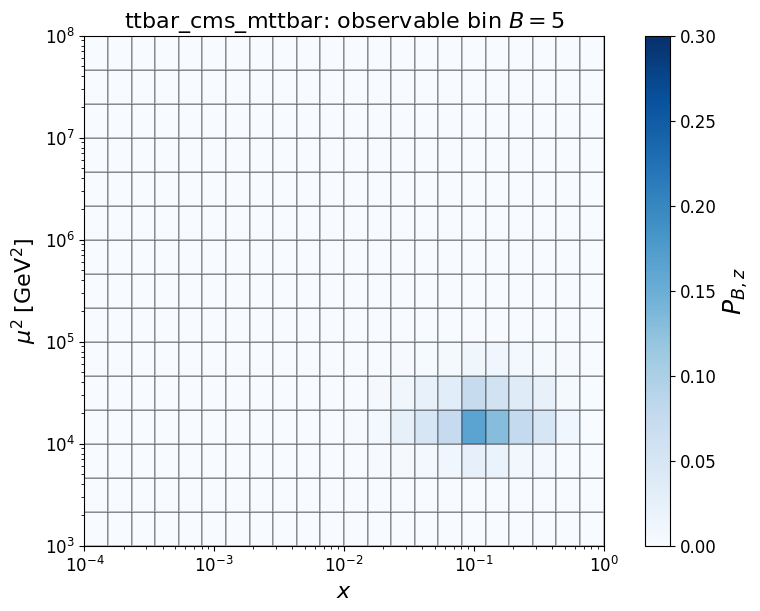

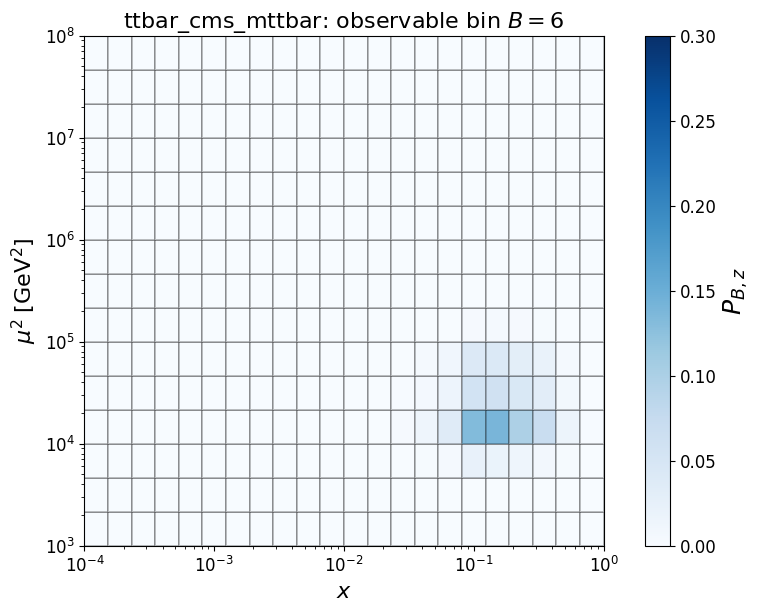

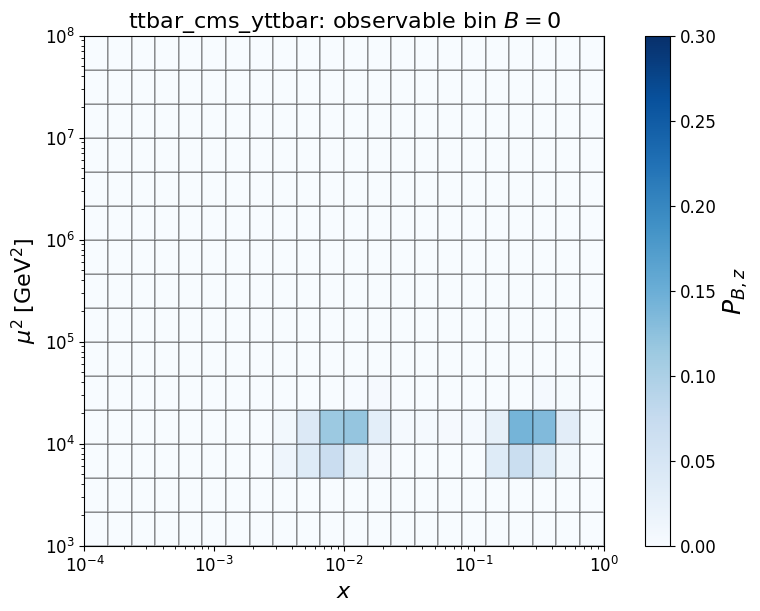

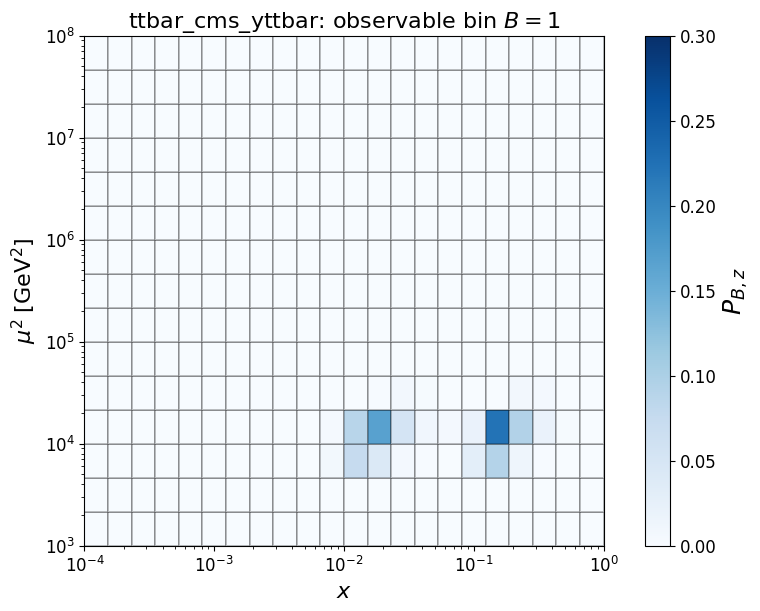

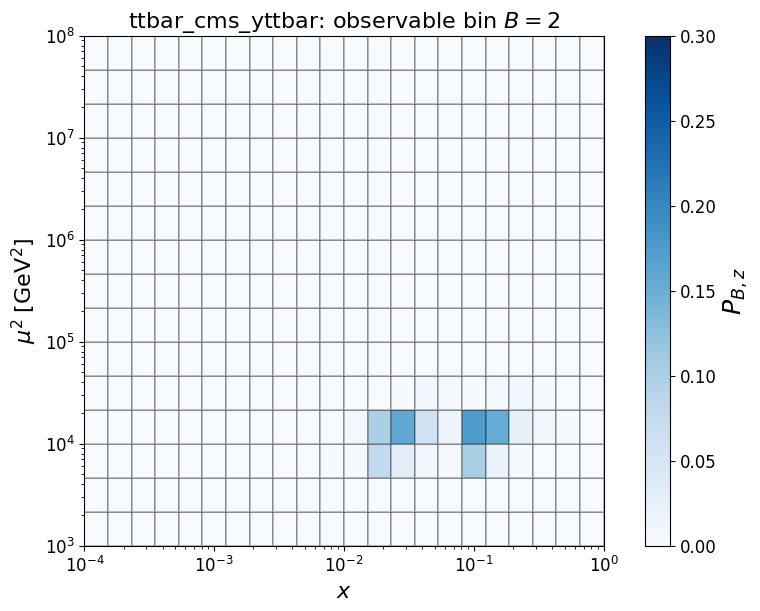

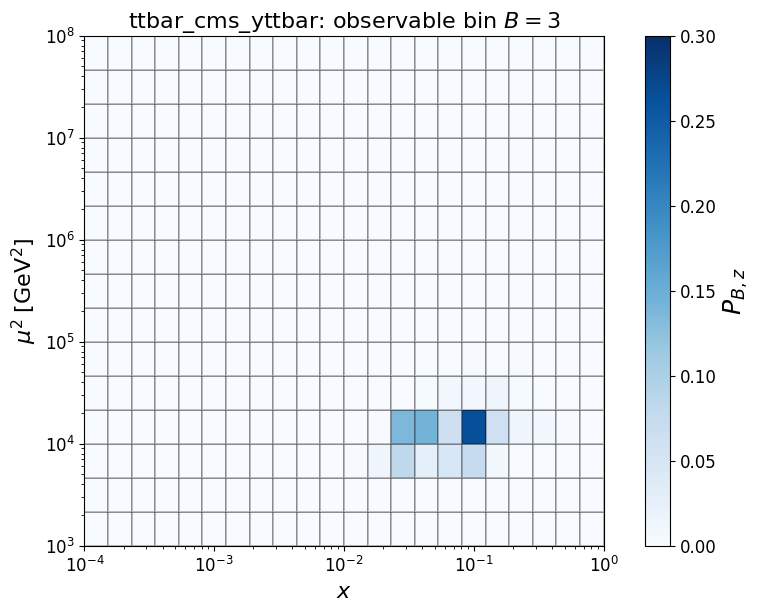

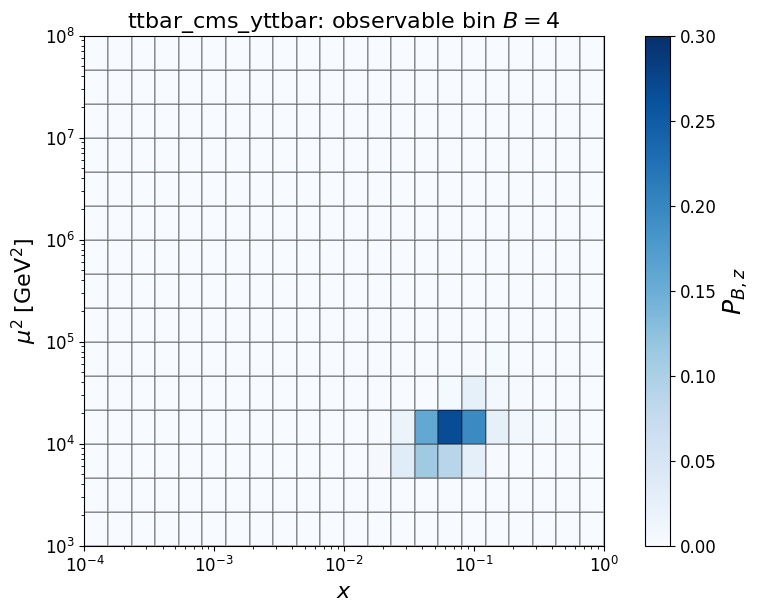

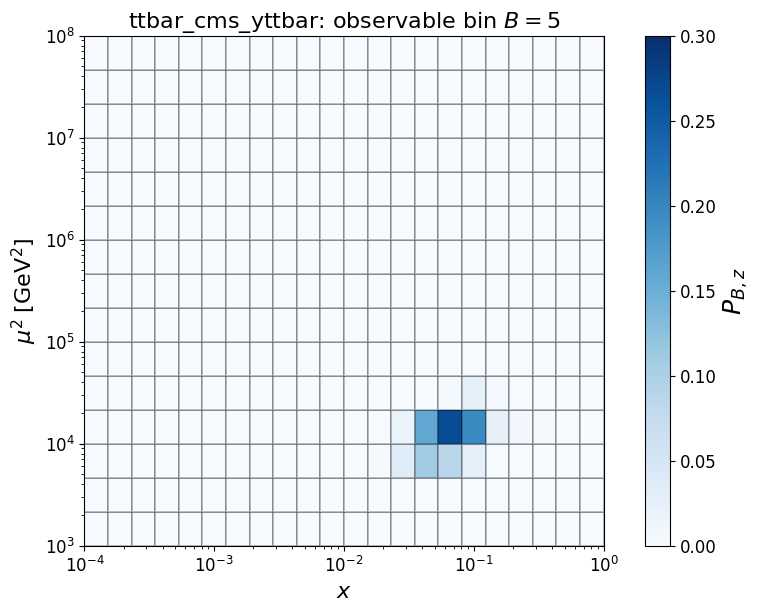

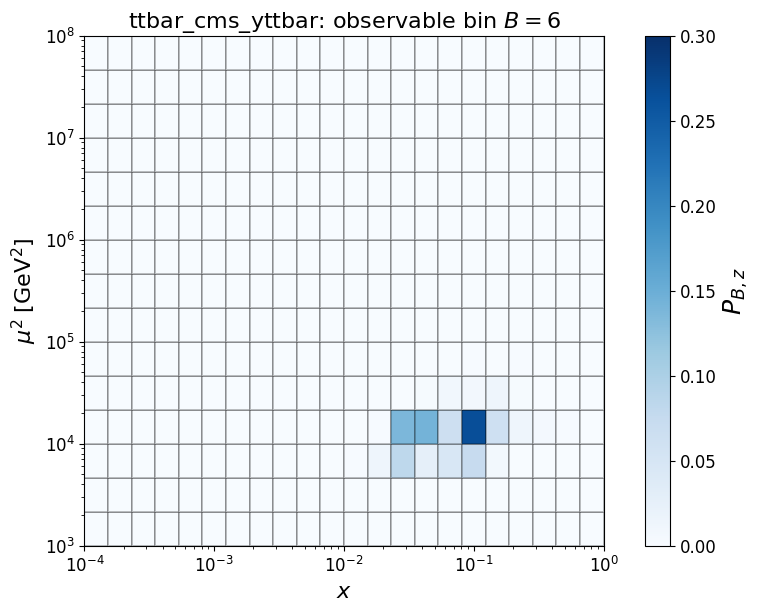

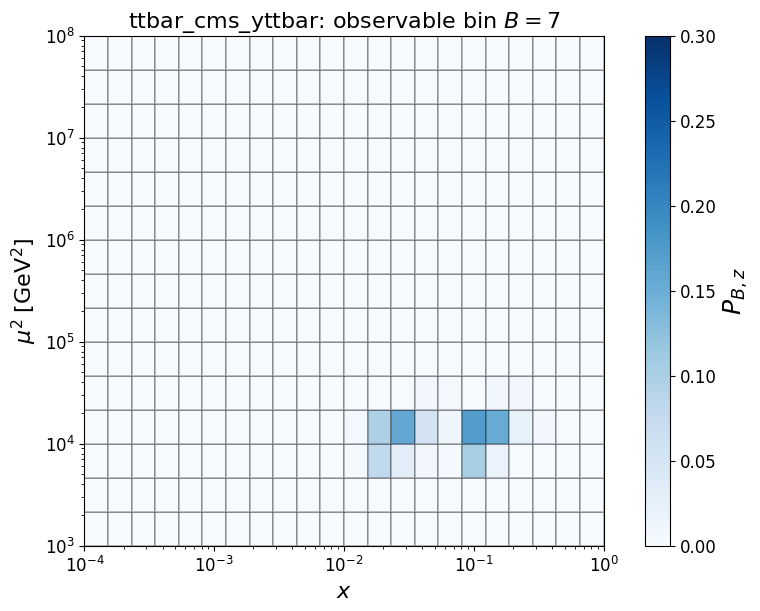

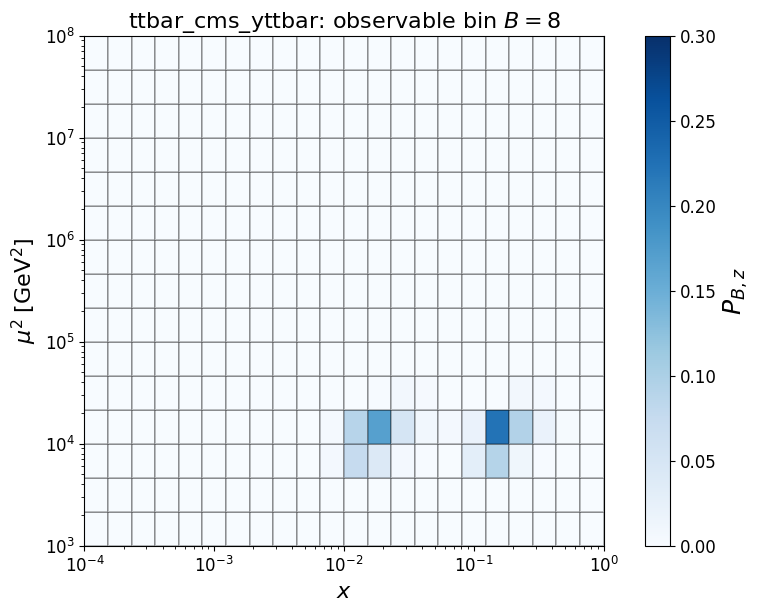

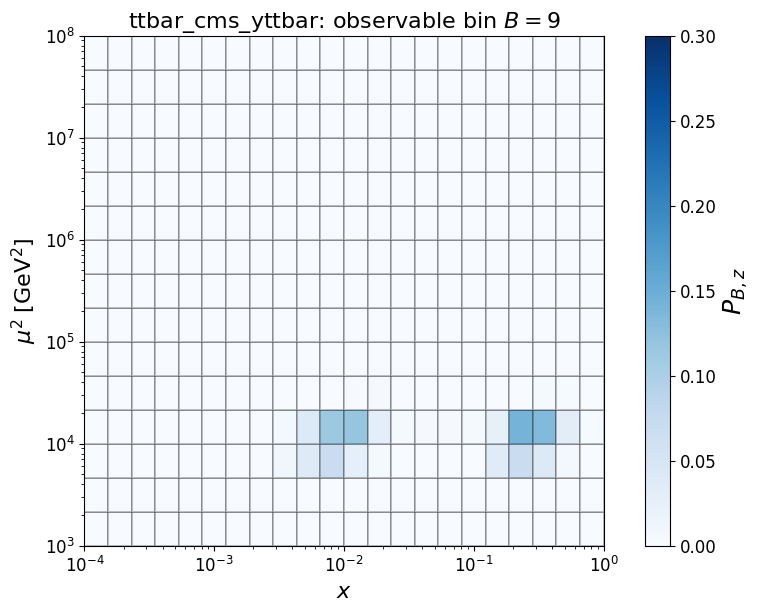

In [111]:

for bin in range(0,7):
    plot_support_bin(
        "/home/jnieh/uni/projects/gridsense/output/data/support/ttbar_cms_mttbar.csv",
        bin,
        color_range=(0.0, 0.3),
    );

for bin in range(0,10):
    plot_support_bin(
        "/home/jnieh/uni/projects/gridsense/output/data/support/ttbar_cms_yttbar.csv",
        bin,
        color_range=(0.0, 0.3),
    );


